<a href="https://colab.research.google.com/github/chitrasavithri176-cmyk/python-ex/blob/main/Olist_Brazilian_Ecommerce_Data_Science_Project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Olist Brazilian E-Commerce — End-to-End Data Science Project



## 1. Install and import libraries

In [12]:
!pip -q install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels nltk tensorflow joblib pyspark

In [13]:
import os, re, json, logging, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("olist_project")

RANDOM_STATE = 42
DATA_DIR = Path("/content/olist_data")
OUTPUT_DIR = Path("/content/olist_outputs")
MODEL_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries ready.")


Libraries ready.


## 2. Load all required CSV files

In [14]:
FILES = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

# Fallback to direct /content if /content/olist_data does not exist or files are directly in /content
import os

def load_csv(filename: str) -> pd.DataFrame:
    path = DATA_DIR / filename
    if not path.exists():
        fallback_path = Path("/content") / filename
        if fallback_path.exists():
            return pd.read_csv(fallback_path)
        raise FileNotFoundError(f"Missing file: {path}. Check DATA_DIR and extract the Kaggle ZIP.")
    return pd.read_csv(path)

data = {name: load_csv(filename) for name, filename in FILES.items()}

for name, frame in data.items():
    logger.info("%s loaded: %s rows, %s columns", name, *frame.shape)

customers = data["customers"].drop_duplicates().copy()
orders = data["orders"].drop_duplicates().copy()
items = data["items"].drop_duplicates().copy()
payments = data["payments"].drop_duplicates().copy()
reviews = data["reviews"].drop_duplicates().copy()
products = data["products"].drop_duplicates().copy()
sellers = data["sellers"].drop_duplicates().copy()
category_translation = data["category_translation"].drop_duplicates().copy()

## 3. Data quality checks and date conversion

In [15]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print("Orders:", orders.shape)
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
display(pd.DataFrame({
    "missing_count": orders.isna().sum(),
    "missing_percent": (orders.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False))


Orders: (99441, 8)
Duplicate order IDs: 0


,missing_count,missing_percent
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
order_purchase_timestamp,0,0.00
order_status,0,0.00
customer_id,0,0.00
order_estimated_delivery_date,0,0.00


## 4. Aggregate one-to-many tables before merging

In [16]:
# One row per order in each aggregate table.
item_agg = items.groupby("order_id").agg(
    item_revenue=("price", "sum"),
    freight_value=("freight_value", "sum"),
    item_count=("order_item_id", "count"),
    unique_products=("product_id", "nunique"),
    first_product_id=("product_id", "first"),
    first_seller_id=("seller_id", "first")
).reset_index()

payment_agg = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_installments=("payment_installments", "max"),
    payment_type=("payment_type", "first")
).reset_index()

review_agg = reviews.groupby("order_id").agg(
    review_score=("review_score", "mean"),
    review_text=("review_comment_message", "first")
).reset_index()

products["product_category_name"] = products["product_category_name"].fillna("unknown")
products = products.merge(category_translation, on="product_category_name", how="left")
products["product_category_name_english"] = products[
    "product_category_name_english"
].fillna(products["product_category_name"])

product_lookup = products[[
    "product_id", "product_category_name_english",
    "product_weight_g", "product_length_cm",
    "product_height_cm", "product_width_cm"
]].drop_duplicates("product_id")

# Item-level analysis table: one row per order item.
item_level = (
    items.merge(orders, on="order_id", how="left")
         .merge(customers, on="customer_id", how="left")
         .merge(product_lookup, on="product_id", how="left")
)

# Order-level analysis table: one row per order.
order_level = (
    orders.merge(customers, on="customer_id", how="left")
          .merge(item_agg, on="order_id", how="left")
          .merge(payment_agg, on="order_id", how="left")
          .merge(review_agg, on="order_id", how="left")
)

order_level["order_revenue"] = order_level["item_revenue"].fillna(0)
order_level["order_total_with_freight"] = (
    order_level["item_revenue"].fillna(0) + order_level["freight_value"].fillna(0)
)

print("Order-level:", order_level.shape)
print("Item-level:", item_level.shape)
print("Unique orders:", order_level["order_id"].nunique())


Order-level: (99441, 25)
Item-level: (112650, 23)
Unique orders: 99441


## 5. EDA — business overview

In [17]:
print("Unique customers:", order_level["customer_unique_id"].nunique())
print("Unique orders:", order_level["order_id"].nunique())
print("Total item revenue (BRL):", round(order_level["order_revenue"].sum(), 2))
print("Average order revenue (BRL):", round(order_level["order_revenue"].mean(), 2))
print("\nOrder status:")
display(order_level["order_status"].value_counts(dropna=False).to_frame("orders"))

print("\nTop categories by item revenue:")
category_revenue = (
    item_level.groupby("product_category_name_english")["price"]
    .sum().sort_values(ascending=False).head(10)
)
display(category_revenue.to_frame("revenue"))


Unique customers: 96096
Unique orders: 99441
Total item revenue (BRL): 13591643.7
Average order revenue (BRL): 136.68

Order status:


,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2



Top categories by item revenue:


,revenue
product_category_name_english,
health_beauty,1258681.34
watches_gifts,1205005.68
bed_bath_table,1036988.68
sports_leisure,988048.97
computers_accessories,911954.32
furniture_decor,729762.49
cool_stuff,635290.85
housewares,632248.66
auto,592720.11


## 6. Feature engineering for analysis

In [18]:
order_level["purchase_year"] = order_level["order_purchase_timestamp"].dt.year
order_level["purchase_month"] = order_level["order_purchase_timestamp"].dt.month
order_level["purchase_dayofweek"] = order_level["order_purchase_timestamp"].dt.dayofweek
order_level["purchase_hour"] = order_level["order_purchase_timestamp"].dt.hour
order_level["purchase_month_period"] = order_level["order_purchase_timestamp"].dt.to_period("M").astype(str)

order_level["delivery_days"] = (
    order_level["order_delivered_customer_date"] -
    order_level["order_purchase_timestamp"]
).dt.total_seconds() / 86400

order_level["estimated_delivery_days"] = (
    order_level["order_estimated_delivery_date"] -
    order_level["order_purchase_timestamp"]
).dt.total_seconds() / 86400

order_level["is_delivered"] = (order_level["order_status"] == "delivered").astype(int)

# A late-delivery label is known only for delivered orders with both dates.
order_level["late_delivery"] = np.where(
    order_level["is_delivered"].eq(1)
    & order_level["order_delivered_customer_date"].notna()
    & order_level["order_estimated_delivery_date"].notna(),
    (order_level["order_delivered_customer_date"] >
     order_level["order_estimated_delivery_date"]).astype(float),
    np.nan
)

display(order_level[[
    "order_id", "order_revenue", "item_count",
    "delivery_days", "late_delivery"
]].head())


,order_id,order_revenue,item_count,delivery_days,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,1.0,8.436574,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,1.0,13.782037,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,1.0,9.394213,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,1.0,13.208750,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,1.0,2.873877,0.0


## 7. Statistics — delivery delay and review score

In [19]:
stats_data = order_level.dropna(subset=["late_delivery", "review_score"]).copy()
late_scores = stats_data.loc[stats_data["late_delivery"] == 1, "review_score"]
ontime_scores = stats_data.loc[stats_data["late_delivery"] == 0, "review_score"]

print("Late-delivery review mean:", late_scores.mean())
print("On-time review mean:", ontime_scores.mean())

if len(late_scores) and len(ontime_scores):
    u_stat, p_value = stats.mannwhitneyu(late_scores, ontime_scores, alternative="two-sided")
    print("Mann-Whitney U:", u_stat, "| p-value:", p_value)
    print("Interpretation:", "Evidence of a difference (p < 0.05)." if p_value < 0.05
          else "No statistically significant difference (p >= 0.05).")
else:
    print("Not enough observations in both delivery groups.")


Late-delivery review mean: 2.566505678109907
On-time review mean: 4.294292012144172
Mann-Whitney U: 150680825.5 | p-value: 0.0
Interpretation: Evidence of a difference (p < 0.05).


## 8. Data visualization

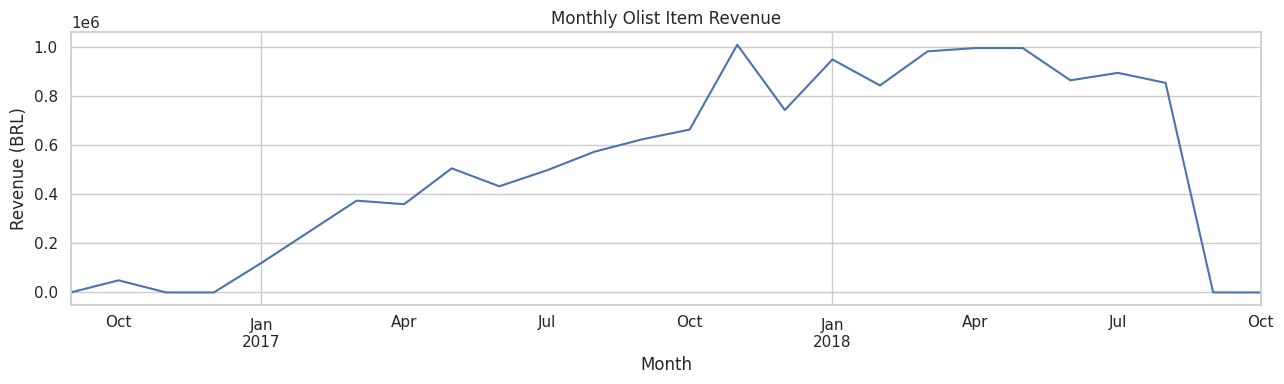

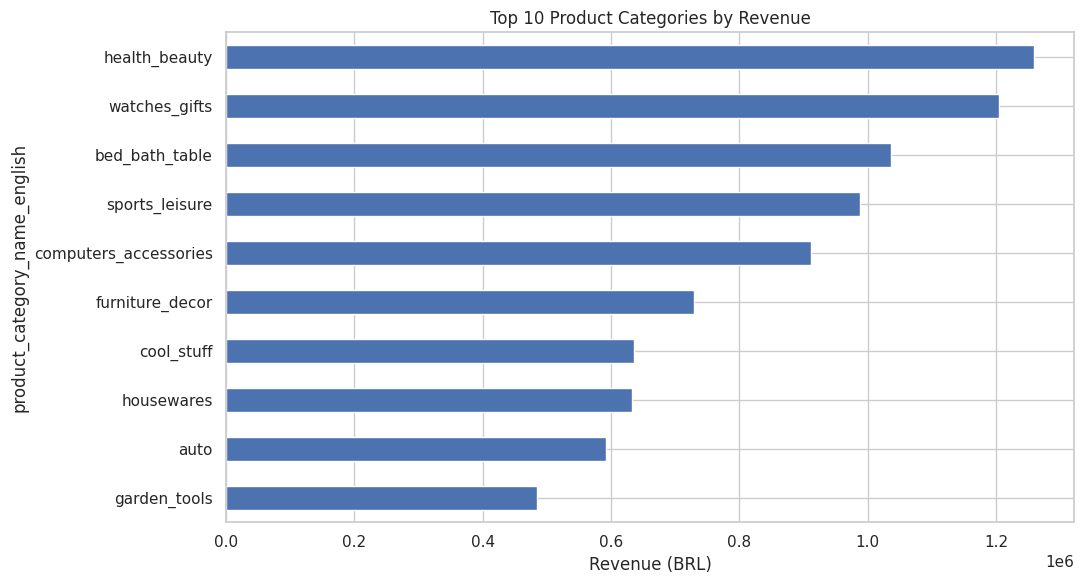

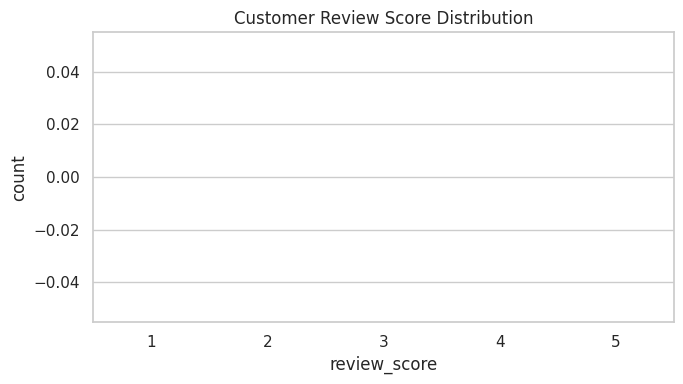

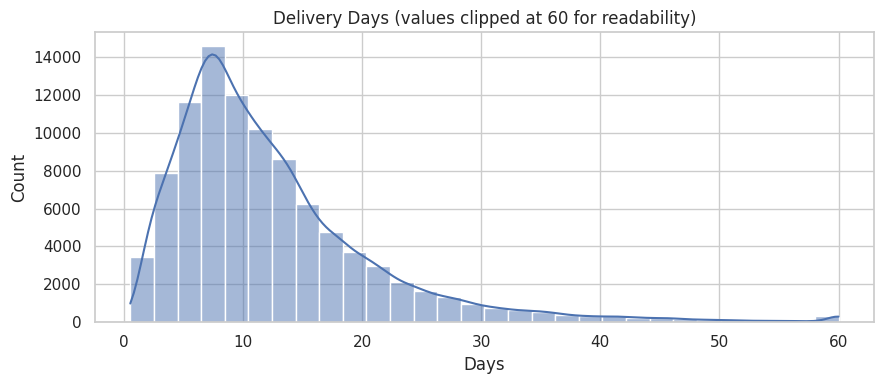

In [20]:
# Monthly revenue
monthly_revenue = (
    order_level.dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")
    .resample("MS")["order_revenue"].sum()
)

plt.figure(figsize=(13, 4))
monthly_revenue.plot()
plt.title("Monthly Olist Item Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

# Top product categories
plt.figure(figsize=(11, 6))
category_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

# Review distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=order_level, x="review_score", order=[1, 2, 3, 4, 5])
plt.title("Customer Review Score Distribution")
plt.tight_layout()
plt.show()

# Delivery time distribution
plt.figure(figsize=(9, 4))
sns.histplot(order_level["delivery_days"].dropna().clip(upper=60), bins=30, kde=True)
plt.title("Delivery Days (values clipped at 60 for readability)")
plt.xlabel("Days")
plt.tight_layout()
plt.show()


## 9. Supervised learning — predict late delivery

In [11]:
# Only delivered orders with a known target are eligible.
ml = order_level.dropna(subset=["late_delivery"]).copy()
ml["late_delivery"] = ml["late_delivery"].astype(int)

# Features chosen to be available at/near purchase time.
# Exclude actual delivery dates, review scores, post-delivery fields and future customer aggregates.
feature_cols = [
    "order_revenue", "freight_value", "item_count",
    "unique_products", "payment_value", "payment_installments",
    "purchase_month", "purchase_dayofweek", "purchase_hour",
    "customer_state", "customer_city"
]
feature_cols = [c for c in feature_cols if c in ml.columns]

X = ml[feature_cols].copy()
y = ml["late_delivery"].copy()

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, min_samples_leaf=2,
        class_weight="balanced", random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

trained_models = {}
metric_rows = []

for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    trained_models[name] = pipe
    metric_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0)
    })

classification_metrics = pd.DataFrame(metric_rows).sort_values("f1", ascending=False)
display(classification_metrics)


,model,accuracy,precision,recall,f1
1,Random Forest,0.825801,0.178827,0.319489,0.229305
0,Logistic Regression,0.656992,0.122516,0.523962,0.198595


## 10. Evaluation and tuning

Best baseline model: Random Forest
              precision    recall  f1-score   support

           0       0.94      0.87      0.90     17729
           1       0.18      0.32      0.23      1565

    accuracy                           0.83     19294
   macro avg       0.56      0.59      0.57     19294
weighted avg       0.87      0.83      0.85     19294



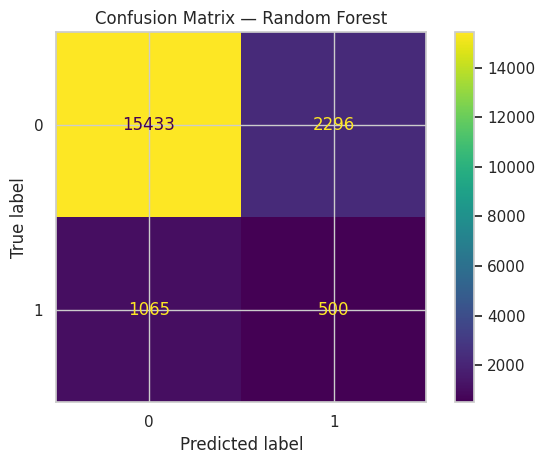

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [ ]:
best_name = classification_metrics.iloc[0]["model"]
best_model = trained_models[best_name]
best_pred = best_model.predict(X_test)

print("Best baseline model:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

# Tune Random Forest using a compact grid.
rf_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ))
])
param_grid = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 15],
    "model__min_samples_leaf": [1, 3]
}
grid = GridSearchCV(
    rf_pipeline, param_grid, cv=3,
    scoring="f1", n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)
tuned_model = grid.best_estimator_
tuned_pred = tuned_model.predict(X_test)
print("Best parameters:", grid.best_params_)
print("Tuned test F1:", f1_score(y_test, tuned_pred, zero_division=0))


## 11. Supervised regression — estimate delivery duration

In [ ]:
reg = order_level.dropna(subset=["delivery_days"]).copy()
reg = reg[reg["delivery_days"].between(0, 90)]
reg_features = [
    "order_revenue", "freight_value", "item_count",
    "payment_installments", "purchase_month",
    "purchase_dayofweek", "purchase_hour",
    "customer_state"
]
reg_features = [c for c in reg_features if c in reg.columns]
Xr = reg[reg_features]
yr = reg["delivery_days"]

num_r = Xr.select_dtypes(include=np.number).columns.tolist()
cat_r = Xr.select_dtypes(exclude=np.number).columns.tolist()
prep_r = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), num_r),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_r)
])

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=RANDOM_STATE
)
reg_model = Pipeline([
    ("preprocess", prep_r),
    ("model", RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
reg_model.fit(Xr_train, yr_train)
yr_pred = reg_model.predict(Xr_test)
print("MAE days:", mean_absolute_error(yr_test, yr_pred))
print("RMSE days:", np.sqrt(mean_squared_error(yr_test, yr_pred)))
print("R2:", r2_score(yr_test, yr_pred))


## 12. Unsupervised learning — customer segmentation

In [ ]:
# Customer-level RFM-style features.
# This is descriptive segmentation over the full historical dataset, not a prospective prediction.
reference_date = order_level["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
customer_features = (
    order_level.dropna(subset=["order_purchase_timestamp"])
    .groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_revenue", "sum")
    )
    .reset_index()
)
customer_features["recency_days"] = (
    reference_date - customer_features["last_purchase"]
).dt.days

seg_cols = ["recency_days", "frequency", "monetary"]
seg_data = customer_features[seg_cols].replace([np.inf, -np.inf], np.nan)
seg_data = seg_data.fillna(seg_data.median())

seg_scaler = StandardScaler()
seg_scaled = seg_scaler.fit_transform(seg_data)

kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
customer_features["segment"] = kmeans.fit_predict(seg_scaled)

segment_profile = customer_features.groupby("segment")[seg_cols].mean().round(2)
display(segment_profile)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=customer_features, x="frequency", y="monetary",
    hue="segment", palette="tab10"
)
plt.title("Customer Segments")
plt.tight_layout()
plt.show()


## 13. Time series forecasting — monthly revenue with ARIMA

In [ ]:
# Monthly revenue series; chronological split prevents random time leakage.
monthly = (
    order_level.dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")["order_revenue"]
    .resample("MS").sum()
)
monthly = monthly.asfreq("MS").fillna(0)

plt.figure(figsize=(12, 4))
monthly.plot()
plt.title("Monthly Revenue")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

if len(monthly) < 24:
    print("Warning: fewer than 24 monthly observations; forecasts may be unstable.")

split_at = max(1, int(len(monthly) * 0.8))
ts_train, ts_test = monthly.iloc[:split_at], monthly.iloc[split_at:]

# ARIMA(2,1,2) baseline. Compare orders / seasonal models for a stronger final study.
arima_fit = ARIMA(ts_train, order=(2, 1, 2)).fit()
ts_forecast = arima_fit.forecast(steps=len(ts_test))

if len(ts_test):
    print("Forecast MAE:", mean_absolute_error(ts_test, ts_forecast))
    print("Forecast RMSE:", np.sqrt(mean_squared_error(ts_test, ts_forecast)))

plt.figure(figsize=(12, 4))
plt.plot(ts_train.index, ts_train, label="Train")
plt.plot(ts_test.index, ts_test, label="Actual")
if len(ts_test):
    plt.plot(ts_test.index, ts_forecast, label="Forecast")
plt.legend()
plt.title("ARIMA — Actual vs Forecast")
plt.tight_layout()
plt.show()

future_revenue = arima_fit.forecast(steps=6)
display(future_revenue.rename("forecast_revenue").to_frame())


## 14. NLP — Portuguese review sentiment

In [ ]:
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Weak labels derived from review stars. This does not replace human-labelled sentiment data.
text_data = order_level.dropna(subset=["review_text", "review_score"]).copy()
text_data["review_text"] = text_data["review_text"].astype(str)
text_data = text_data[text_data["review_text"].str.strip().ne("")]
text_data["sentiment"] = np.select(
    [text_data["review_score"] <= 2, text_data["review_score"] == 3,
     text_data["review_score"] >= 4],
    ["negative", "neutral", "positive"],
    default="unknown"
)
text_data = text_data[text_data["sentiment"] != "unknown"]

pt_stopwords = set(stopwords.words("portuguese"))

def clean_portuguese_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zà-ÿ\s]", " ", text)
    tokens = [w for w in text.split() if w not in pt_stopwords and len(w) > 2]
    return " ".join(tokens)

text_data["clean_text"] = text_data["review_text"].apply(clean_portuguese_text)
text_data = text_data[text_data["clean_text"].str.len() > 0]

X_text = text_data["clean_text"]
y_text = text_data["sentiment"]

Xtr, Xte, ytr, yte = train_test_split(
    X_text, y_text, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_text
)
tfidf = TfidfVectorizer(max_features=12000, ngram_range=(1, 2), min_df=2)
Xtr_vec = tfidf.fit_transform(Xtr)
Xte_vec = tfidf.transform(Xte)

nlp_model = LogisticRegression(
    max_iter=1200, class_weight="balanced"
)
nlp_model.fit(Xtr_vec, ytr)
nlp_pred = nlp_model.predict(Xte_vec)
print(classification_report(yte, nlp_pred, zero_division=0))


## 15. Deep learning — neural network for late-delivery classification

In [ ]:
# TensorFlow model using numeric features only.
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from sklearn.utils.class_weight import compute_class_weight

deep_cols = [
    "order_revenue", "freight_value", "item_count",
    "unique_products", "payment_value", "payment_installments",
    "purchase_month", "purchase_dayofweek", "purchase_hour"
]
deep_cols = [c for c in deep_cols if c in ml.columns]
deep_frame = ml[deep_cols].copy()
deep_target = ml["late_delivery"].astype(int)

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    deep_frame, deep_target, test_size=0.2,
    random_state=RANDOM_STATE, stratify=deep_target
)

deep_prep = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
Xd_train_scaled = deep_prep.fit_transform(Xd_train)
Xd_test_scaled = deep_prep.transform(Xd_test)

class_values = np.unique(yd_train)
class_weights_arr = compute_class_weight(
    class_weight="balanced", classes=class_values, y=yd_train
)
class_weights = dict(zip(class_values, class_weights_arr))

tf.keras.utils.set_random_seed(RANDOM_STATE)
nn_model = Sequential([
    Input(shape=(Xd_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.25),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])
nn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.AUC(name="auc"), "accuracy"]
)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
history = nn_model.fit(
    Xd_train_scaled, yd_train,
    validation_split=0.2, epochs=20, batch_size=128,
    class_weight=class_weights, callbacks=[early_stop],
    verbose=1
)
nn_prob = nn_model.predict(Xd_test_scaled, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)
print(classification_report(yd_test, nn_pred, zero_division=0))


## 16. Recommendation system — item-based collaborative filtering

In [ ]:
# Build a sparse customer-product interaction matrix.
# Limit to products with enough interactions to keep similarity computation manageable.
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

interactions = items[["order_id", "product_id"]].merge(
    orders[["order_id", "customer_id"]], on="order_id", how="inner"
).merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id", how="left"
).dropna(subset=["customer_unique_id", "product_id"])

popular_products = interactions["product_id"].value_counts()
eligible_products = popular_products[popular_products >= 5].index
interactions = interactions[interactions["product_id"].isin(eligible_products)]

# Use a bounded product set for a practical Colab demonstration.
top_product_ids = popular_products.loc[
    popular_products.index.intersection(eligible_products)
].head(1500).index
interactions = interactions[interactions["product_id"].isin(top_product_ids)]

customer_codes, customer_uniques = pd.factorize(interactions["customer_unique_id"])
product_codes, product_uniques = pd.factorize(interactions["product_id"])

matrix = csr_matrix(
    (np.ones(len(interactions)), (customer_codes, product_codes)),
    shape=(len(customer_uniques), len(product_uniques))
)

# Item-item cosine similarity.
item_similarity = cosine_similarity(matrix.T, dense_output=True)
item_similarity_df = pd.DataFrame(
    item_similarity, index=product_uniques, columns=product_uniques
)

def recommend_similar_products(product_id, top_n=5):
    if product_id not in item_similarity_df.columns:
        return pd.Series(dtype=float, name="similarity")
    return (
        item_similarity_df[product_id]
        .drop(index=product_id)
        .sort_values(ascending=False)
        .head(top_n)
        .rename("similarity")
    )

if len(product_uniques):
    example_product = product_uniques[0]
    print("Example product:", example_product)
    display(recommend_similar_products(example_product, 5).to_frame())


## 17. Big Data — PySpark demonstration

In [ ]:
# Run after the Pandas sections. Local[*] uses available local CPU cores.
from pyspark.sql import SparkSession
from pyspark.sql.functions import count, sum as spark_sum, col

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("OlistEcommerceAnalytics")
    .getOrCreate()
)

spark_orders = spark.read.csv(
    str(DATA_DIR / FILES["orders"]),
    header=True, inferSchema=True
)
spark_items = spark.read.csv(
    str(DATA_DIR / FILES["items"]),
    header=True, inferSchema=True
)
spark_customers = spark.read.csv(
    str(DATA_DIR / FILES["customers"]),
    header=True, inferSchema=True
)

print("Spark orders:", spark_orders.count())
spark_customers.groupBy("customer_state").agg(
    count("*").alias("customer_rows")
).orderBy(col("customer_rows").desc()).show(10)

spark_items.groupBy("product_id").agg(
    spark_sum("price").alias("item_revenue")
).orderBy(col("item_revenue").desc()).show(10)

spark.stop()


## 18. **Streamlit development** — interactive web application
Streamlit turns the project outputs and trained model into a small interactive web app.

In [ ]:
# Save the Streamlit app and requirements file into the project output folder.
# Run this cell after completing the model export section.

streamlit_app_code = r'''from pathlib import Path
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Olist Data Science Dashboard", page_icon="🛒", layout="wide")

# Expected folder structure:
# app.py
# olist_outputs/
#   olist_sales_powerbi.csv
#   customer_segments.csv
#   monthly_revenue.csv
#   future_revenue_forecast.csv (optional)
#   review_sentiment_results.csv (optional)
#   models/late_delivery_model.joblib

ROOT = Path(__file__).resolve().parent
OUTPUT_DIR = ROOT / "olist_outputs"
MODEL_DIR = OUTPUT_DIR / "models"

@st.cache_data
def load_csv(filename):
    path = OUTPUT_DIR / filename
    return pd.read_csv(path) if path.exists() else pd.DataFrame()

@st.cache_resource
def load_model():
    path = MODEL_DIR / "late_delivery_model.joblib"
    return joblib.load(path) if path.exists() else None

sales = load_csv("olist_sales_powerbi.csv")
segments = load_csv("customer_segments.csv")
monthly = load_csv("monthly_revenue.csv")
forecast = load_csv("future_revenue_forecast.csv")
sentiment = load_csv("review_sentiment_results.csv")

st.title("Olist Brazilian E-Commerce — Data Science App")
st.caption("Interactive Streamlit application built from the Olist final project outputs.")

if sales.empty:
    st.error("Sales data not found. Place olist_sales_powerbi.csv inside the olist_outputs folder.")
    st.stop()

# Parse dates and apply a date filter
if "order_purchase_timestamp" in sales.columns:
    sales["order_purchase_timestamp"] = pd.to_datetime(
        sales["order_purchase_timestamp"], errors="coerce"
    )

with st.sidebar:
    st.header("Dashboard filters")
    if "customer_state" in sales.columns:
        states = sorted(sales["customer_state"].dropna().astype(str).unique())
        selected_states = st.multiselect("Customer state", states, default=states)
        if selected_states:
            sales_view = sales[sales["customer_state"].astype(str).isin(selected_states)].copy()
        else:
            sales_view = sales.iloc[0:0].copy()
    else:
        sales_view = sales.copy()

    if "order_purchase_timestamp" in sales_view.columns:
        valid_dates = sales_view["order_purchase_timestamp"].dropna()
        if not valid_dates.empty:
            start_date = valid_dates.min().date()
            end_date = valid_dates.max().date()
            date_range = st.date_input("Purchase date range", value=(start_date, end_date))
            if isinstance(date_range, tuple) and len(date_range) == 2:
                sales_view = sales_view[
                    sales_view["order_purchase_timestamp"].dt.date.between(
                        date_range[0], date_range[1]
                    )
                ]

revenue_col = "order_revenue" if "order_revenue" in sales_view.columns else None
orders_count = sales_view["order_id"].nunique() if "order_id" in sales_view.columns else len(sales_view)
revenue = sales_view[revenue_col].sum() if revenue_col else 0
aov = revenue / orders_count if orders_count else 0
customers = sales_view["customer_unique_id"].nunique() if "customer_unique_id" in sales_view.columns else 0

c1, c2, c3, c4 = st.columns(4)
c1.metric("Total orders", f"{orders_count:,}")
c2.metric("Item revenue", f"R$ {revenue:,.2f}")
c3.metric("Average order value", f"R$ {aov:,.2f}")
c4.metric("Unique customers", f"{customers:,}")

tab1, tab2, tab3, tab4 = st.tabs(
    ["Sales analysis", "Customer segments", "Delivery prediction", "Review sentiment"]
)

with tab1:
    st.subheader("Sales overview")
    if revenue_col and "order_purchase_timestamp" in sales_view.columns:
        trend = (sales_view.dropna(subset=["order_purchase_timestamp"])
                 .set_index("order_purchase_timestamp")
                 .resample("MS")[revenue_col].sum())
        st.line_chart(trend)
    if "customer_state" in sales_view.columns and revenue_col:
        state_sales = (sales_view.groupby("customer_state", as_index=False)[revenue_col]
                       .sum().sort_values(revenue_col, ascending=False).head(10))
        st.write("Top 10 states by revenue")
        st.bar_chart(state_sales.set_index("customer_state"))
    st.dataframe(sales_view.head(500), use_container_width=True)

    if not monthly.empty:
        st.subheader("Monthly revenue series")
        st.dataframe(monthly, use_container_width=True)
    if not forecast.empty:
        st.subheader("Future revenue forecast")
        st.dataframe(forecast, use_container_width=True)

with tab2:
    st.subheader("Customer segmentation")
    if segments.empty:
        st.info("customer_segments.csv was not found in olist_outputs.")
    else:
        st.write("Customer-level RFM-style features and cluster assignments.")
        st.dataframe(segments.head(500), use_container_width=True)
        cluster_col = next((c for c in ["cluster", "customer_cluster", "segment"] if c in segments.columns), None)
        if cluster_col:
            st.bar_chart(segments[cluster_col].value_counts().sort_index())

with tab3:
    st.subheader("Late delivery prediction")
    model = load_model()
    if model is None:
        st.warning("Model file not found. Run the model-training and export cells in the notebook first.")
    else:
        st.write("Enter order details to estimate whether an order may be delivered late.")
        with st.form("prediction_form"):
            a, b, c = st.columns(3)
            with a:
                order_revenue = st.number_input("Order revenue (BRL)", min_value=0.0, value=150.0)
                freight_value = st.number_input("Freight value (BRL)", min_value=0.0, value=20.0)
                item_count = st.number_input("Number of items", min_value=1, value=1, step=1)
                unique_products = st.number_input("Unique products", min_value=1, value=1, step=1)
            with b:
                payment_value = st.number_input("Payment value (BRL)", min_value=0.0, value=170.0)
                payment_installments = st.number_input("Payment installments", min_value=1, value=1, step=1)
                purchase_month = st.selectbox("Purchase month", list(range(1, 13)), index=5)
                purchase_dayofweek = st.selectbox("Purchase day of week (Mon=0)", list(range(7)))
            with c:
                purchase_hour = st.slider("Purchase hour", 0, 23, 12)
                customer_state = st.text_input("Customer state code", value="SP").upper()
                customer_city = st.text_input("Customer city", value="sao paulo").lower()
            submitted = st.form_submit_button("Predict delivery status")

        if submitted:
            input_df = pd.DataFrame([{
                "order_revenue": order_revenue,
                "freight_value": freight_value,
                "item_count": item_count,
                "unique_products": unique_products,
                "payment_value": payment_value,
                "payment_installments": payment_installments,
                "purchase_month": purchase_month,
                "purchase_dayofweek": purchase_dayofweek,
                "purchase_hour": purchase_hour,
                "customer_state": customer_state,
                "customer_city": customer_city
            }])
            try:
                prediction = int(model.predict(input_df)[0])
                if hasattr(model, "predict_proba"):
                    probability = float(model.predict_proba(input_df)[0][1])
                    st.metric("Estimated late-delivery probability", f"{probability:.1%}")
                if prediction == 1:
                    st.warning("Model prediction: Late delivery")
                else:
                    st.success("Model prediction: On-time delivery")
                st.caption("This is a model estimate, not a guaranteed delivery date.")
            except Exception as exc:
                st.error(f"Prediction could not be generated: {exc}")

with tab4:
    st.subheader("Customer review sentiment")
    if sentiment.empty:
        st.info("review_sentiment_results.csv was not found in olist_outputs.")
    else:
        st.write("Held-out review sentiment predictions from the NLP model.")
        if "predicted_sentiment" in sentiment.columns:
            st.bar_chart(sentiment["predicted_sentiment"].value_counts())
        st.dataframe(sentiment.head(500), use_container_width=True)

st.divider()
st.caption("Academic project demonstration. Predictions and analysis depend on the dataset and trained models.")
'''

(OUTPUT_DIR / "app.py").write_text(streamlit_app_code, encoding="utf-8")
(OUTPUT_DIR / "requirements.txt").write_text(
    "streamlit\\npandas\\njoblib\\nscikit-learn\\nnumpy\\n",
    encoding="utf-8"
)
print("Streamlit files saved:")
print(OUTPUT_DIR / "app.py")
print(OUTPUT_DIR / "requirements.txt")

## 19. Export Power BI tables and model artifacts

In [ ]:
# Map kernel variables to the requested CSV outputs
weekly_sales.rename("revenue").to_csv("sales.csv", index=True)
rfm.reset_index().to_csv("rfm_segments.csv", index=False)

# Extract delivery metrics from orders_df
delivery_cols = ["order_id", "customer_state", "delivery_days", "delay_days", "late_delivery"]
delivery_df = orders_df[[col for col in delivery_cols if col in orders_df.columns]].copy()
delivery_df.to_csv("delivery.csv", index=False)

# Save the forecast dataframe
forecast_df.to_csv("forecast.csv", index=False)

print("Project dataframes successfully saved as CSV files!")

**Conclusion**

This project combines data cleaning, exploratory analysis, statistical testing, visualization, feature engineering, classification, regression, clustering, model tuning, ARIMA forecasting, Portuguese review NLP, neural networks, collaborative filtering, PySpark, and Power BI.

Before presenting: report the actual metrics produced by your run; do not invent accuracy or forecast values. Discuss class imbalance, historical data limitations, rating-derived sentiment labels, and recommendation-system coverage as project limitations.